# Difusión térmica 1D: explicación de los códigos

Este cuaderno es una guía para entender y ejecutar los cuatro ejemplos:

1. **Dirichlet:** temperaturas impuestas en ambos extremos.
2. **Neumann:** temperatura impuesta a la izquierda y extremo derecho aislado.
3. **Robin:** intercambio por convección con aire de temperatura variable.
4. **Calor interno:** difusión con un aporte dentro de la barra.

Los bloques de parámetros, inicialización y actualización se toman directamente
de los archivos recibidos. Se intercalan explicaciones y gráficos para estudiar
qué hace cada línea y cómo se interpreta físicamente. Los gráficos se presentan
con rótulos acordes a las operaciones activas de cada ejemplo.

## Cómo usarlo

Seleccionar el kernel **Python 3.12 (Proyecto 2)** y ejecutar las celdas en orden.
Para reproducirlo completo, reiniciar el kernel y ejecutar todas las celdas.
Cada ejemplo vuelve a definir sus parámetros: un cambio en un ejemplo no se
transfiere automáticamente a los demás.

El cuaderno conserva su ejecución y sus figuras. Los bloques numéricos se ejecutan
aquí sin abrir ventanas ni crear carpetas junto a los archivos originales.

## 1. Preparar las herramientas

`numpy` permite trabajar con la temperatura de todos los nodos como un arreglo.
`matplotlib` permite graficar perfiles espaciales e historias temporales.
Un perfil es la temperatura en distintas posiciones en un mismo instante;
una historia temporal sigue una posición a lo largo del tiempo.

In [1]:
from pathlib import Path
import os
import numpy as np

ubicacion = Path.cwd().resolve()
raiz = next((p for p in (ubicacion, *ubicacion.parents)
             if (p / "casos/1d/codigos").is_dir()), None)
if raiz is None:
    raise RuntimeError("Abrir este cuaderno dentro de la carpeta del proyecto.")
os.environ.setdefault("MPLCONFIGDIR", str(raiz / ".venv" / "cache" / "matplotlib"))
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.figsize": (8, 4.8), "axes.grid": True, "grid.alpha": 0.25})
print("NumPy:", np.__version__)
print("Herramientas listas.")

NumPy: 2.5.4
Herramientas listas.


## 2. La física que comparten los ejemplos

Si la temperatura cambia con la posición, existe conducción. La ley de Fourier es:

$$q_x''=-k\frac{\partial T}{\partial x}.$$

El signo negativo expresa que el calor fluye hacia temperaturas menores.
Para un segmento de volumen $V$, el balance es:

$$\text{almacenamiento}=\text{entrada}-\text{salida}+\text{generación}.$$

Con propiedades constantes:

$$\rho c_p\frac{\partial T}{\partial t}
=k\frac{\partial^2T}{\partial x^2}+\dot q_v,$$

o, dividiendo por la capacidad térmica por unidad de volumen:

$$\frac{\partial T}{\partial t}
=\alpha\frac{\partial^2T}{\partial x^2}+S,
\qquad\alpha=\frac{k}{\rho c_p},\qquad S=\frac{\dot q_v}{\rho c_p}.$$

| Magnitud | Significado | Unidad |
|---|---|---|
| $T$ | Temperatura | °C |
| $k$ | Conductividad: facilidad para transmitir calor | W/(m·K) |
| $\rho$ | Densidad: masa por volumen | kg/m³ |
| $c_p$ | Calor específico: energía por masa y aumento de temperatura | J/(kg·K) |
| $\alpha$ | Difusividad: conducción respecto del almacenamiento | m²/s |
| $q_x''$ | Flujo por unidad de área | W/m² |
| $\dot q_v$ | Potencia generada por unidad de volumen | W/m³ |
| $S$ | Tasa de aumento térmico debida a la fuente | K/s |

$\rho c_p V$ tiene unidades J/K: indica cuánta energía hace falta para aumentar
en un grado la temperatura del volumen. Una conductividad alta no implica por
sí sola una difusividad alta: también intervienen $\rho$ y $c_p$.

Los cambios de temperatura tienen el mismo valor numérico en K y °C.
Los ejemplos sin calor interno usan $S=0$.

## 3. Condición inicial y condiciones de borde

La **condición inicial** indica cómo está la temperatura en todo el dominio
cuando empieza el cálculo. Las **condiciones de borde** indican qué ocurre en
los extremos durante la evolución.

| Borde | Qué se prescribe | Expresión | Interpretación |
|---|---|---|---|
| Dirichlet | Temperatura | $T=T_b$ | Un contacto ideal mantiene la temperatura. |
| Neumann | Flujo saliente | $-k\nabla T\cdot\mathbf n=q_n''$ | Si $q_n''=0$, el borde es adiabático. |
| Robin | Relación entre flujo y temperatura | $-k\nabla T\cdot\mathbf n=h(T_s-T_\infty)$ | La superficie intercambia calor con el aire. |

$\mathbf n$ es la normal que apunta hacia afuera del sólido. En Robin,
$h$ [W/(m²·K)] mide la intensidad del intercambio. $T_s$ es la temperatura del
sólido en la superficie y $T_\infty$ la del ambiente: pueden ser diferentes.

**Adiabático** significa que no atraviesa calor esa frontera; no significa que
su temperatura sea fija. Puede calentarse por conducción desde el interior.

## 4. Cómo aparece el código de diferencias finitas

La barra se divide en nodos $x_i=i\Delta x$. Con `nx` nodos hay `nx-1`
intervalos, de modo que $\Delta x=L/(nx-1)$.

FTCS usa una diferencia hacia adelante en tiempo y una diferencia centrada en espacio:

$$\frac{T_i^{n+1}-T_i^n}{\Delta t}
=\alpha\frac{T_{i+1}^n-2T_i^n+T_{i-1}^n}{\Delta x^2}.$$

Despejando:

$$T_i^{n+1}=T_i^n+r(T_{i+1}^n-2T_i^n+T_{i-1}^n),
\qquad r=\frac{\alpha\Delta t}{\Delta x^2}.$$

Los tres primeros ejemplos usan esta actualización en los nodos interiores.
En el cuarto aparece además el aporte de calor interno.

| Expresión de Python | Nodos representados |
|---|---|
| `T[0]`, `T[-1]` | Primer y último nodo |
| `T[1:-1]` | Todos los nodos interiores |
| `Told[:-2]` | Vecinos izquierdos de los nodos interiores |
| `Told[2:]` | Vecinos derechos de los nodos interiores |

`Told = T.copy()` conserva el instante anterior. Es necesario para que todos los
vecinos de una actualización pertenezcan al mismo tiempo. `Told = T` compartiría
el mismo arreglo y no crearía esa copia independiente.

In [2]:
# Ejercicio pequeño para leer el stencil: cinco nodos y r = 0.25.
perfil_anterior = np.array([20., 24., 28., 24., 20.])
perfil_nuevo = perfil_anterior.copy()
perfil_nuevo[1:-1] = perfil_anterior[1:-1] + 0.25 * (
    perfil_anterior[2:] - 2*perfil_anterior[1:-1] + perfil_anterior[:-2]
)
print("Anterior:", perfil_anterior)
print("Nuevo:   ", perfil_nuevo)
# En el centro: 28 + 0.25*(24 - 2*28 + 24) = 26 °C.

Anterior: [20. 24. 28. 24. 20.]
Nuevo:    [20. 24. 26. 24. 20.]


## 5. El paso de tiempo y la estabilidad

Para difusión pura 1D con este esquema y propiedades constantes:

$$r\leq\frac12,\qquad\Delta t\leq\frac{\Delta x^2}{2\alpha}.$$

La actualización puede escribirse como una combinación de temperaturas con
pesos $(1-2r),r,r$. Con $0\leq r\leq1/2$ esos pesos son no negativos y suman uno.
Si se reduce $\Delta x$ a la mitad, el máximo paso estable cae a la cuarta parte.
Un cálculo estable aún puede tener error: estabilidad y precisión son conceptos distintos.

El cálculo temporal de los ejemplos sigue esta secuencia:

```python
dt = r_target * dx**2 / alpha
nsteps = int(np.ceil(t_end / dt))
dt = t_end / nsteps
r = alpha * dt / dx**2
```

`ceil` redondea el número de pasos hacia arriba. El reajuste hace que todos los
pasos tengan igual duración y que el último coincida con `t_end`.
El ejemplo Robin agrega la restricción que introduce el intercambio superficial.

# Ejemplo 1. Dirichlet: temperaturas fijas en los extremos

Archivo: [01_1d_dirichlet_verification.py](../casos/1d/codigos/01_1d_dirichlet_verification.py).

Una barra de 1 m parte a 20 °C en su interior. Los extremos se mantienen en
0 °C y 10 °C. El calor sale hacia esos contactos y el perfil se vuelve asimétrico.

## 6. Parámetros, malla e inicialización

`alpha` se ingresa directamente. `A = 0*50.0` vale **cero**: el seno escrito en
la inicialización no aporta temperatura en esta ejecución.
Con `nx=101` se obtienen 100 intervalos de 0,01 m. El tiempo final es 4500 s.

In [3]:
L = 1.0                 # m
alpha = 1.0e-4          # m^2/s
Tizq = 0.0               # °C
Tder = 10.0               # °C
Tini = 20.
A = 0*50.0                # °C

nx = 101
x = np.linspace(0.0, L, nx)
dx = x[1] - x[0]

# FTCS explícito. En 1D: r <= 1/2
r_target = 0.45
dt = r_target * dx**2 / alpha
t_end = 3*1500.0
nsteps = int(np.ceil(t_end / dt))
dt = t_end / nsteps
r = alpha * dt / dx**2

T = Tini + A * np.sin(np.pi * x / L)
T[0] = Tizq
T[-1] = Tder

# Seis perfiles equiespaciados en el tiempo para mostrar la difusión.
snapshot_steps = np.rint(np.linspace(0, nsteps, 20)).astype(int)
snapshots = {0: T.copy()}

`np.linspace` crea posiciones uniformemente espaciadas. Después de construir el
perfil interior se asignan `T[0]` y `T[-1]`. Por eso la instantánea inicial ya
tiene los contactos a 0 y 10 °C, aunque el resto esté a 20 °C.

`snapshot_steps` elige 20 pasos, aproximadamente equiespaciados. El diccionario
`snapshots` guarda copias de esos perfiles. Guardar `T.copy()` evita que los
perfiles almacenados cambien cuando se actualiza el arreglo.

El comentario del archivo dice “seis perfiles”, pero la instrucción activa pide
20. Los valores ejecutados determinan el resultado.

## 7. Bucle de actualización

Se actualiza solo el interior con FTCS y se vuelven a imponer los extremos.
`if n in snapshot_steps` decide cuándo conservar una imagen del campo térmico.

In [4]:
for n in range(1, nsteps + 1):
    Told = T.copy()
    T[1:-1] = Told[1:-1] + r * (
        Told[2:] - 2.0*Told[1:-1] + Told[:-2]
    )
    T[0] = Tizq
    T[-1] = Tder

    if n in snapshot_steps:
        snapshots[n] = T.copy()

dx = 0.01000 m; dt = 0.45000 s; r = 0.45000
Pasos = 10000; tiempo final = 4500.0 s
Temperatura del centro al final = 5.224830 °C


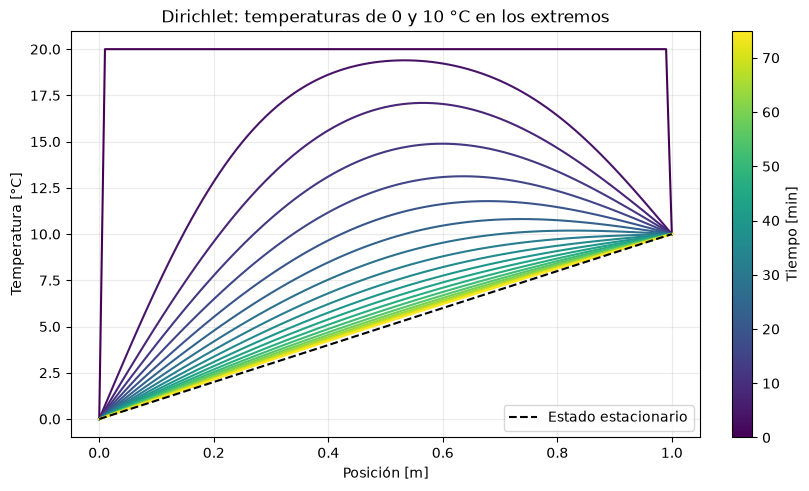

In [5]:
dirichlet_resultado = {"x": x.copy(), "T": T.copy(), "snapshots": snapshots,
                       "dt": dt, "nsteps": nsteps}
print(f"dx = {dx:.5f} m; dt = {dt:.5f} s; r = {r:.5f}")
print(f"Pasos = {nsteps}; tiempo final = {nsteps*dt:.1f} s")
print(f"Temperatura del centro al final = {T[nx//2]:.6f} °C")

fig, ax = plt.subplots(layout="constrained")
for paso in snapshot_steps:
    ax.plot(x, snapshots[paso], color=plt.cm.viridis(paso/nsteps))
ax.plot(x, Tizq+(Tder-Tizq)*x/L, "k--", label="Estado estacionario")
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, t_end/60), cmap="viridis"),
             ax=ax, label="Tiempo [min]")
ax.set(xlabel="Posición [m]", ylabel="Temperatura [°C]", title="Dirichlet: temperaturas de 0 y 10 °C en los extremos")
ax.legend()
plt.show()

## 8. Qué significa el resultado

Sin generación y en equilibrio, la segunda derivada espacial se anula. El perfil
estacionario es una recta:

$$T_{est}(x)=T_{izq}+(T_{der}-T_{izq})x/L.$$

El centro tiende a 5 °C. A los 4500 s todavía está aproximadamente a 5,22483 °C.
La diferencia con 5 °C indica que el proceso aún es transiente; no mide el error numérico.

En el archivo las instrucciones `Texact`, `err_inf` y su impresión están comentadas
con `#`: **no se ejecutan**. Las referencias a “exacta” y a marcadores en la
leyenda no significan que se esté calculando una solución exacta en esa ejecución.
Aquí los perfiles de colores representan las temperaturas calculadas.

# Ejemplo 2. Neumann: un extremo adiabático

Archivo: [03_1d_neumann.py](../casos/1d/codigos/03_1d_neumann.py).

La barra empieza a 20 °C. A la izquierda se impone 60 °C; a la derecha no hay
flujo. El calor entra por la izquierda y se redistribuye sin salir por la derecha.

## 9. Parámetros e inicialización

`np.full(nx, Tini)` llena el arreglo con la temperatura inicial. En este archivo
`T[0] = T_left` aparece dentro del bucle. Por eso la instantánea `snapshots[0]`
contiene 20 °C también en el primer nodo, y la temperatura izquierda de 60 °C
se asigna al completar el primer paso. El primer cálculo interior utiliza esa
fila inicial de 20 °C. Este detalle permite leer correctamente la secuencia temporal.

In [6]:
L = 1.0
alpha = 1.0e-4
Tini = 20.0       # °C: temperatura inicial de la barra
T_left = 60.0     # °C: temperatura impuesta en x=0

nx = 101
x = np.linspace(0.0, L, nx)
dx = x[1] - x[0]

r_target = 0.45
dt = r_target*dx**2/alpha
t_end = 3*6000.0
nsteps = int(np.ceil(t_end/dt))
dt = t_end/nsteps
r = alpha*dt/dx**2

T = np.full(nx, Tini)

# x=0: Dirichlet T=T_left
# x=L: Neumann adiabático dT/dx=0
snapshot_steps = np.rint(np.linspace(0, nsteps, 20)).astype(int)
snapshots = {0: T.copy()}

## 10. Por qué aparece el factor 2 en el borde derecho

La condición adiabática es $\partial T/\partial x=0$ en $x=L$. Para usar una
derivada centrada se introduce un nodo imaginario o **ghost node** fuera de la barra:

$$\frac{T_{ghost}-T_{N-1}}{2\Delta x}=0
\quad\Longrightarrow\quad T_{ghost}=T_{N-1}.$$

Al sustituirlo en el laplaciano del último nodo:

$$\frac{T_{ghost}-2T_N+T_{N-1}}{\Delta x^2}
=\frac{2(T_{N-1}-T_N)}{\Delta x^2}.$$

Así se obtiene la línea:

```python
T[-1] = Told[-1] + 2*r*(Told[-2] - Told[-1])
```

El extremo adiabático puede cambiar de temperatura, aunque el flujo que lo
atraviesa sea cero. También puede interpretarse como el balance de medio
volumen de control en el borde.

In [7]:
for n in range(1, nsteps+1):
    Told = T.copy()

    T[1:-1] = Told[1:-1] + r*(
        Told[2:] - 2*Told[1:-1] + Told[:-2]
    )

    T[0] = T_left

    # Ghost node:
    # dT/dx = 0 => T_ghost = T[-2]
    # Laplaciano en el borde => 2(T[-2]-T[-1])/dx^2
    T[-1] = Told[-1] + 2*r*(Told[-2] - Told[-1])

    if n in snapshot_steps:
        snapshots[n] = T.copy()

Tiempo final = 5.00 h; r = 0.45000
Extremo izquierdo al final = 60.0000 °C
Extremo adiabático al final = 59.4001 °C


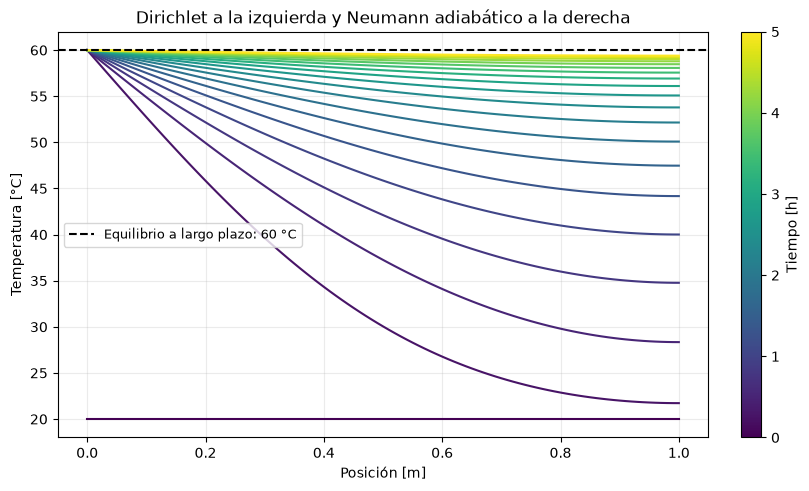

In [8]:
neumann_resultado = {"x": x.copy(), "T": T.copy(), "snapshots": snapshots,
                     "dt": dt, "nsteps": nsteps}
print(f"Tiempo final = {nsteps*dt/3600:.2f} h; r = {r:.5f}")
print(f"Extremo izquierdo al final = {T[0]:.4f} °C")
print(f"Extremo adiabático al final = {T[-1]:.4f} °C")

fig, ax = plt.subplots(layout="constrained")
for paso in snapshot_steps:
    ax.plot(x, snapshots[paso], color=plt.cm.viridis(paso/nsteps))
ax.axhline(T_left, color="black", linestyle="--", label="Equilibrio a largo plazo: 60 °C")
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, t_end/3600), cmap="viridis"),
             ax=ax, label="Tiempo [h]")
ax.set(xlabel="Posición [m]", ylabel="Temperatura [°C]", title="Dirichlet a la izquierda y Neumann adiabático a la derecha")
ax.legend(fontsize=9)
plt.show()

## 11. Interpretación física

En equilibrio la recta de temperatura debe tener pendiente cero en el extremo
adiabático. Con 60 °C a la izquierda, toda la barra tiende a 60 °C.
El tiempo final de 18000 s es un tiempo de observación, no la imposición del equilibrio.

La energía total aumenta por el calor que entra a la izquierda. Que el extremo
derecho sea adiabático no vuelve adiabático a todo el sistema.

# Ejemplo 3. Robin: convección y ambiente oscilante

Archivo: [04_1d_robin.py](../casos/1d/codigos/04_1d_robin.py).

La losa parte a 20 °C. El aire izquierdo oscila entre 10 y 30 °C con un período
de 12 h; el derecho permanece a 20 °C. Ahora las temperaturas de las superficies
se calculan mediante un balance, no se fijan iguales a la del aire.

## 12. Parámetros, ambiente y registro de resultados

En este ejemplo sí se definen `k`, `rho` y `cp`, y se calcula `alpha=k/(rho*cp)`.
El coeficiente `h=12` tiene unidades W/(m²·K).

$$T_{\infty,izq}(t)=20+10\sin(2\pi t/period).$$

El aire está a 30 °C en 3 h y a 10 °C en 9 h; en 0, 6 y 12 h está a 20 °C.
La simulación dura 48 h, mientras que los perfiles de `snapshot_hours` cubren
solo las primeras 10 h. Las historias registran puntos a lo largo de la simulación.

In [9]:
# Losa 1D inicialmente caliente, expuesta por ambos extremos a convección.
L = 1.0             # m
k = 2.0             # W/(m K)
rho = 2400.0        # kg/m^3
cp = 900.0          # J/(kg K)
alpha = k/(rho*cp)

h = 12.0                # W/(m^2 K)
Tini = 20.0             # °C: temperatura inicial de la losa
Tinf_right = 20.0       # °C: aire del lado derecho
Tinf_left_mean = 20.0   # °C: valor medio del aire del lado izquierdo
Tinf_left_amp = 10.0    # °C: amplitud; T_inf,izq varía entre 10 y 30 °C
period = 12.0*3600.0    # s: período de la oscilación

nx = 81
x = np.linspace(0.0, L, nx)
dx = x[1]-x[0]

# Paso estable conservador.
dt_diff = 0.40*dx**2/alpha
dt_conv = 0.40*(rho*cp*dx)/(2*h)
dt = min(dt_diff, dt_conv)

t_end = 48*3600.0
nsteps = int(np.ceil(t_end/dt))
dt = t_end/nsteps
r = alpha*dt/dx**2

T = np.full(nx, Tini)

# Perfiles espaciales: 3 h y 9 h son extremos del ciclo de 12 h;
# 6 h y 12 h corresponden a los cruces por la temperatura media.
snapshot_hours = np.linspace(0., 10., 20)
snapshot_steps = np.rint(snapshot_hours*3600.0/dt).astype(int)
snapshots = {0: T.copy()}

times = []
Tcenter = []
Tsurface_left = []
Tsurface_right = []
Tinf_left_history = []

## 13. Derivar la actualización superficial

El nodo superficial representa medio volumen: $V=A_s\Delta x/2$. Recibe calor
por conducción desde el vecino y por convección desde el aire:

$$\rho c_p\frac{A_s\Delta x}{2}\frac{dT_s}{dt}
=\frac{kA_s}{\Delta x}(T_{vecino}-T_s)+hA_s(T_\infty-T_s).$$

Dividiendo por la capacidad térmica y usando Euler explícito:

$$T_s^{n+1}=T_s^n+\Delta t\left[
\frac{2k}{\rho c_p\Delta x^2}(T_{vecino}^n-T_s^n)
+\frac{2h}{\rho c_p\Delta x}(T_\infty^n-T_s^n)\right].$$

Los factores 2 aparecen por el medio volumen. Si el aire está más frío que
la superficie, el término convectivo es negativo y la enfría.

`t=n*dt` evalúa el ambiente en el instante anterior al actualizar. Después del
paso, `T` corresponde a `(n+1)*dt`; por eso las instantáneas se guardan usando
`n+1`, evitando confundir el tiempo anterior con el nuevo.

Las listas `Tcenter`, `Tsurface_left`, `Tsurface_right` y `Tinf_left_history`
permiten comparar el centro, ambas superficies y el aire en el mismo tiempo.

In [10]:
for n in range(nsteps+1):
    if n % max(1, nsteps//400) == 0:
        t = n*dt
        times.append(t/3600.0)
        Tcenter.append(T[nx//2])
        Tsurface_left.append(T[0])
        Tsurface_right.append(T[-1])
        Tinf_left_history.append(
            Tinf_left_mean + Tinf_left_amp*np.sin(2*np.pi*t/period)
        )

    if n == nsteps:
        break

    Told = T.copy()
    t = n*dt
    Tinf_left = Tinf_left_mean + Tinf_left_amp*np.sin(2*np.pi*t/period)

    T[1:-1] = Told[1:-1] + r*(
        Told[2:] - 2*Told[1:-1] + Told[:-2]
    )

    # Balance sobre medio volumen de control en cada borde.
    T[0] = Told[0] + dt * (
        2*k/(rho*cp*dx**2) * (Told[1]-Told[0])
        + 2*h/(rho*cp*dx) * (Tinf_left-Told[0])
    )

    T[-1] = Told[-1] + dt * (
        2*k/(rho*cp*dx**2) * (Told[-2]-Told[-1])
        + 2*h/(rho*cp*dx) * (Tinf_right-Told[-1])
    )

    # Tras el update, T representa el instante (n+1)·dt.
    if (n + 1) in snapshot_steps:
        snapshots[n + 1] = T.copy()

## 14. Estabilidad con convección

Definamos $Bi_\Delta=h\Delta x/k$. El peso de la temperatura superficial anterior es:

$$1-2r(1+Bi_\Delta).$$

Para que todos los pesos sean no negativos en esta actualización se requiere:

$$r(1+Bi_\Delta)\leq\frac12,$$

además de la condición interior. El código elige un dt conservador a partir de
dos escalas y lo reajusta al tiempo final. Aquí calculamos el coeficiente
combinado para comprobar estos parámetros concretos. No basta asumir que la
fórmula de difusión pura cubre cualquier condición Robin.

alpha = 9.25925926e-07 m²/s; dt efectivo = 67.5000 s
r = 0.40000; Bi_dx = 0.07500
r*(1+Bi_dx) = 0.43000; límite = 0.5
Límite combinado de dt = 78.4884 s
Simulación completa = 48.00 h
Último tiempo de la historia muestreada = 47.9250 h
Centro al final de la simulación = 20.12815 °C


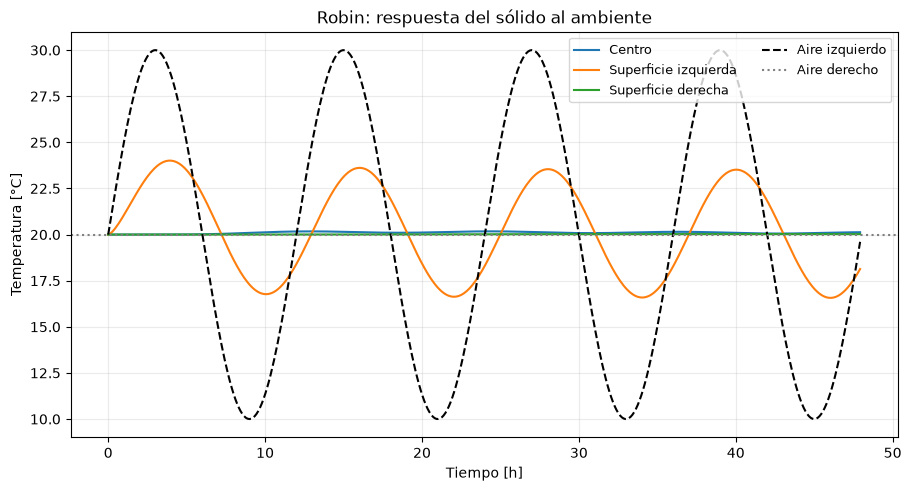

In [11]:
Bi_dx = h*dx/k
dt_limite_robin = 1/(2*alpha/dx**2 + 2*h/(rho*cp*dx))
print(f"alpha = {alpha:.8e} m²/s; dt efectivo = {dt:.4f} s")
print(f"r = {r:.5f}; Bi_dx = {Bi_dx:.5f}")
print(f"r*(1+Bi_dx) = {r*(1+Bi_dx):.5f}; límite = 0.5")
print(f"Límite combinado de dt = {dt_limite_robin:.4f} s")
print(f"Simulación completa = {nsteps*dt/3600:.2f} h")
print(f"Último tiempo de la historia muestreada = {times[-1]:.4f} h")
print(f"Centro al final de la simulación = {T[nx//2]:.5f} °C")

robin_resultado = {"x": x.copy(), "T": T.copy(), "snapshots": snapshots,
                   "dt": dt, "nsteps": nsteps}
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
ax.plot(times, Tcenter, label="Centro")
ax.plot(times, Tsurface_left, label="Superficie izquierda")
ax.plot(times, Tsurface_right, label="Superficie derecha")
ax.plot(times, Tinf_left_history, "k--", label="Aire izquierdo")
ax.axhline(Tinf_right, color="gray", linestyle=":", label="Aire derecho")
ax.set(xlabel="Tiempo [h]", ylabel="Temperatura [°C]", title="Robin: respuesta del sólido al ambiente")
ax.legend(fontsize=9, ncol=2)
plt.show()

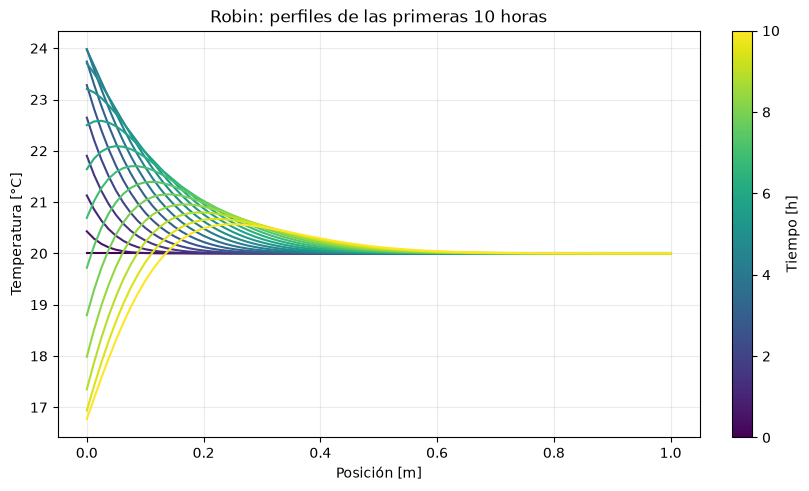

In [12]:
fig, ax = plt.subplots(layout="constrained")
for paso in snapshot_steps:
    ax.plot(x, snapshots[paso], color=plt.cm.viridis(paso*dt/(10*3600)))
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 10), cmap="viridis"),
             ax=ax, label="Tiempo [h]")
ax.set(xlabel="Posición [m]", ylabel="Temperatura [°C]", title="Robin: perfiles de las primeras 10 horas")
plt.show()

## 15. Cómo interpretar el desfase

La superficie izquierda responde al ambiente primero. El interior responde con
menor amplitud y retraso por el almacenamiento térmico y la difusión.
No hay razón para que el centro alcance instantáneamente la temperatura del aire.

La historia se muestrea cada `max(1, nsteps//400)` pasos. El último instante
registrado puede ser anterior a 48 h si el último paso no coincide con ese
intervalo. El campo final `T`, en cambio, sí corresponde al tiempo final.

`snapshot_hours` se convierte a pasos enteros mediante redondeo. El tiempo
efectivo de un perfil es `paso*dt`, que puede diferir levemente de la hora pedida.

# Ejemplo 4. Calor interno

Archivo: [05_calor_interno.py](../casos/1d/codigos/05_calor_interno.py).

La barra empieza a 0 °C y ambos extremos se mantienen a 0 °C. Se incorpora
un aporte positivo dentro de cada nodo interior, por lo que la barra se calienta
y simultáneamente conduce calor hacia los extremos.

## 16. Parámetros e inicialización

`Q0 = 5./6000` aparece dentro del paréntesis multiplicado por `r`.
Leer su posición en la ecuación es esencial para interpretar sus unidades.

In [13]:
L = 1.0                 # m
alpha = 1.0e-4          # m^2/s
Tizq = 0.0               # °C
Tder = 0.0               # °C
Tini = 0.
A = 0*50.0                # °C
Q0 = 5./6000



nx = 101
x = np.linspace(0.0, L, nx)
dx = x[1] - x[0]

# FTCS explícito. En 1D: r <= 1/2
r_target = 0.45
dt = r_target * dx**2 / alpha
t_end = 3*1500.0
nsteps = int(np.ceil(t_end / dt))
dt = t_end / nsteps
r = alpha * dt / dx**2

T = Tini + A * np.sin(np.pi * x / L)
T[0] = Tizq
T[-1] = Tder

# Seis perfiles equiespaciados en el tiempo para mostrar la difusión.
snapshot_steps = np.rint(np.linspace(0, nsteps, 20)).astype(int)
snapshots = {0: T.copy()}

## 17. El aporte que suma la línea de actualización

La operación activa es:

```python
T[1:-1] = Told[1:-1] + r * (
    Told[2:] - 2.0*Told[1:-1] + Told[:-2] + Q0
)
```

En cada paso la fuente aporta **`r*Q0`** a la temperatura interior.
La forma física de una fuente en la PDE sería:

$$T_i^{n+1}=T_i^n+r\delta_{xx}T_i^n+\Delta t\,S,
\qquad S=\frac{\dot q_v}{\rho c_p}.$$

Por lo tanto, la línea escrita equivale a:

$$S_{efectiva}=\frac{rQ_0}{\Delta t}=\frac{\alpha Q_0}{\Delta x^2}.$$

El archivo no declara unidades para `Q0`. Para que la suma dentro del paréntesis
sea dimensionalmente consistente, `Q0` se interpreta como un incremento térmico
discreto en K. **No es directamente una potencia en W/m³.** Con esta malla,
$\alpha/\Delta x^2$ vale numéricamente 1 s⁻¹ y la tasa efectiva es
$0,00083333$ K/s. Esa coincidencia numérica no elimina los factores de unidades.

Si se refina la malla manteniendo `Q0` constante, la fuente efectiva cambia como
$1/\Delta x^2$. Para mantener una fuente física $S$ fija habría que definir
$Q_0=S\Delta x^2/\alpha$, o escribir el aporte como `dt*S`.
El bloque siguiente ejecuta la expresión recibida tal como está escrita.

In [14]:
for n in range(1, nsteps + 1):
    Told = T.copy()
    T[1:-1] = Told[1:-1] + r * (
        Told[2:] - 2.0*Told[1:-1] + Told[:-2] + Q0
    )
    T[0] = Tizq
    T[-1] = Tder

    if n in snapshot_steps:
        snapshots[n] = T.copy()

Q0 = 0.00083333; r = 0.45000
Aumento por fuente en cada paso = 0.00037500 K
Tasa térmica efectiva = 0.00083333 K/s
Temperatura central al final = 1.029010 °C
Temperaturas de los extremos = 0.0, 0.0 °C


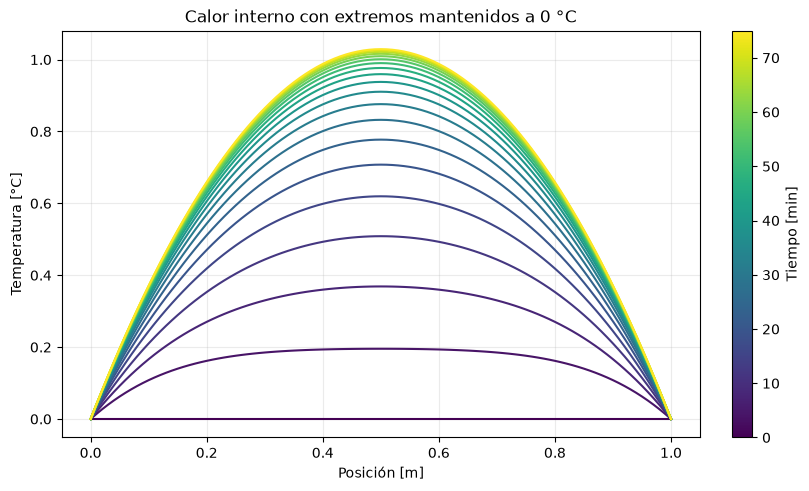

In [15]:
S_efectiva = r*Q0/dt
calor_resultado = {"x": x.copy(), "T": T.copy(), "snapshots": snapshots,
                   "dt": dt, "nsteps": nsteps, "S_efectiva": S_efectiva}
print(f"Q0 = {Q0:.8f}; r = {r:.5f}")
print(f"Aumento por fuente en cada paso = {r*Q0:.8f} K")
print(f"Tasa térmica efectiva = {S_efectiva:.8f} K/s")
print(f"Temperatura central al final = {T[nx//2]:.6f} °C")
print(f"Temperaturas de los extremos = {T[0]:.1f}, {T[-1]:.1f} °C")

fig, ax = plt.subplots(layout="constrained")
for paso in snapshot_steps:
    ax.plot(x, snapshots[paso], color=plt.cm.viridis(paso/nsteps))
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, t_end/60), cmap="viridis"),
             ax=ax, label="Tiempo [min]")
ax.set(xlabel="Posición [m]", ylabel="Temperatura [°C]", title="Calor interno con extremos mantenidos a 0 °C")
plt.show()

## 18. Balance entre generación y salida de calor

La temperatura no aumenta indefinidamente: los extremos a 0 °C extraen calor.
Para una fuente efectiva constante, el equilibrio satisface:

$$0=\alpha\frac{d^2T}{dx^2}+S_{efectiva}.$$

Con ambos bordes a cero, la solución estacionaria es parabólica:

$$T_{est}(x)=\frac{S_{efectiva}}{2\alpha}x(L-x).$$

Esta expresión permite entender la forma del perfil y su tendencia a largo plazo.
No es una solución exacta del transiente.

El término constante de este ejemplo ilustra generación interna. Un modelo
de hidratación necesitaría además justificar la fuente y su evolución con
la edad y, cuando corresponda, con la historia térmica del hormigón.

## 19. Leer las gráficas y los archivos

Los cuatro scripts comparten instrucciones para graficar:

- `plt.subplots(...)` crea la figura y los ejes.
- `ax.plot(x, perfil, ...)` dibuja la temperatura contra la posición.
- `snapshots[paso]` recupera el campo guardado en un instante.
- `paso*dt` es el tiempo físico de esa instantánea.
- `label`, `legend`, `xlabel` y `ylabel` describen curvas y unidades.
- `plt.show()` muestra una figura y `plt.close(fig)` libera sus recursos.

Los scripts usan `Path` para definir `FIG` y ahora guardan su figura con
`fig.savefig(...)` en la carpeta fija del caso dentro de `resultados/1d/`, antes
de mostrarla. El ejecutor sin opciones guarda esas mismas figuras sin abrir
ventanas; Robin conserva sus dos paneles. En este cuaderno las figuras quedan
guardadas también dentro de las salidas del archivo `.ipynb`.

Los bloques que empiezan por `#` son comentarios, no operaciones activas.
Los textos de títulos o leyendas no cambian la ecuación que se ejecuta.

## 20. Qué deberíamos poder explicar en la revisión oral

1. Qué almacena $\rho c_p V$ y qué representa la ley de Fourier.
2. La diferencia entre conductividad y difusividad.
3. La diferencia entre perfil inicial y condición de borde.
4. Por qué hay un intervalo menos que nodos.
5. Cómo se obtiene el stencil y por qué se copia el estado anterior.
6. Qué cambia entre temperatura fija, flujo nulo y convección.
7. De dónde viene el factor 2 de los bordes Neumann y Robin.
8. Cómo cambia el paso estable al refinar y por qué Robin necesita su propio balance.
9. Por qué el aire y la superficie pueden tener distintas temperaturas.
10. Qué suma realmente `r*Q0` y cómo distinguir W/m³ de K/s.

## Fuentes para estudiar

- [Códigos y guías](../Enunciados%20e%20Instrucciones/README.md).
- [Guía extensa de difusión](../Enunciados%20e%20Instrucciones/Guias/DIFUSION_DE_CALOR_1D_2D_3D.md).
- [G05: difusión térmica y balances](../Enunciados%20e%20Instrucciones/Guias/G05_DIFUSION_TERMICA_FD.md).
- [Requisitos y preparación de E01](../entregas/E01/README.md).

Los ejemplos permiten estudiar los mecanismos por separado. Aplicarlos a la
fundación requerirá justificar materiales, geometría, secuencia constructiva,
hidratación y fronteras reales.